In [1]:
from pathlib import Path
import collections
import glob
import os

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats
from scipy.stats import mannwhitneyu, shapiro, ttest_ind, ttest_rel, wilcoxon

# Load the data

In [2]:
# Locate the data directory whether Jupyter starts in the repository root
# or in the notebook directory.
project_candidates = (Path.cwd(), *Path.cwd().parents)
project_root = next(
    (path for path in project_candidates if (path / "data" / "NAC" / "txt").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate data/NAC/txt from the current directory.")

home = project_root / "data" / "NAC" / "txt"

In [3]:
# Analysis parameters and plotting colors.
region = "NAC"
time_exm = 30*60
cocaine_time = 60*60
injection_time = 1*60
bin_time = 5
bins = np.arange(-time_exm,time_exm+injection_time+bin_time,bin_time)
color_VEH = "tab:blue"
color_COC = "tab:orange"

In [4]:
def barplot_annotate_brackets(num1, num2, data, center, height, yerr=None, dh=.05, barh=.05, fs=None, maxasterix=4):
    """
    Annotate barplot with p-values.

    :param num1: number of left bar to put bracket over
    :param num2: number of right bar to put bracket over
    :param data: string to write or number for generating asterixes
    :param center: centers of all bars (like plt.bar() input)
    :param height: heights of all bars (like plt.bar() input)
    :param yerr: yerrs of all bars (like plt.bar() input)
    :param dh: height offset over bar / bar + yerr in axes coordinates (0 to 1)
    :param barh: bar height in axes coordinates (0 to 1)
    :param fs: font size
    :param maxasterix: maximum number of asterixes to write (for very small p-values)
    """

    if type(data) is str:
        text = data
    else:
        # * is p < 0.05
        # ** is p < 0.005
        # *** is p < 0.0005
        # etc.
        text = ''
        p = .05

        while data < p:
            text += '*'
            p /= 10.

            if maxasterix and len(text) == maxasterix:
                break

        if len(text) == 0:
            text = 'N.S., p = {:.2f}'.format(data)

    lx, ly = center[num1], height[num1]
    rx, ry = center[num2], height[num2]

    if yerr:
        ly += yerr[num1]
        ry += yerr[num2]

    ax_y0, ax_y1 = plt.gca().get_ylim()
    dh *= (ax_y1 - ax_y0)
    barh *= (ax_y1 - ax_y0)

    y = max(ly, ry) + dh

    barx = [lx, lx, rx, rx]
    bary = [y, y+barh, y+barh, y]
    mid = ((lx+rx)/2, y+barh)

    plt.plot(barx, bary, c='black')

    kwargs = dict(ha='center', va='bottom')
    if fs is not None:
        kwargs['fontsize'] = fs

    plt.text(*mid, text, **kwargs)

In [5]:
# Discover all spike-time text files in a deterministic order.
extension = 'txt'
files = glob.glob('{}/*.{}'.format(home,extension))
files.sort()
files

['/media/mirtilo/ab1ceb4b-3786-4306-ad57-08c212a1d5dd/cholinergic-NAc-adaptation/data/NAC/txt/NAC_COC21_time_cluster_shank_sua.txt',
 '/media/mirtilo/ab1ceb4b-3786-4306-ad57-08c212a1d5dd/cholinergic-NAc-adaptation/data/NAC/txt/NAC_COC23_time_cluster_shank_sua.txt',
 '/media/mirtilo/ab1ceb4b-3786-4306-ad57-08c212a1d5dd/cholinergic-NAc-adaptation/data/NAC/txt/NAC_COC24_time_cluster_shank_sua.txt',
 '/media/mirtilo/ab1ceb4b-3786-4306-ad57-08c212a1d5dd/cholinergic-NAc-adaptation/data/NAC/txt/NAC_COC25_time_cluster_shank_sua.txt',
 '/media/mirtilo/ab1ceb4b-3786-4306-ad57-08c212a1d5dd/cholinergic-NAc-adaptation/data/NAC/txt/NAC_COC310_time_cluster_shank_sua.txt',
 '/media/mirtilo/ab1ceb4b-3786-4306-ad57-08c212a1d5dd/cholinergic-NAc-adaptation/data/NAC/txt/NAC_COC311_time_cluster_shank_sua.txt',
 '/media/mirtilo/ab1ceb4b-3786-4306-ad57-08c212a1d5dd/cholinergic-NAc-adaptation/data/NAC/txt/NAC_COC312_time_cluster_shank_sua.txt',
 '/media/mirtilo/ab1ceb4b-3786-4306-ad57-08c212a1d5dd/cholinergic-

In [6]:
# Extract the experimental group and animal identifier from each filename.
def detect_file_type(file_path):
    base_name = os.path.basename(file_path)
    components = base_name.split('_')
    file_type = components[1]
    return file_type

In [7]:
# Split recordings into vehicle and cocaine groups.
files_VEH = []
files_COC = []

for i in range(len(files)):
    if(detect_file_type(files[i])[:3]=="VEH"):
        files_VEH.append(files[i])

    if(detect_file_type(files[i])[:3]=="COC"):
        files_COC.append(files[i])

In [8]:
# Compute binned firing rates for the vehicle group.
fr_VEH = []
for files in files_VEH:

    old_st, old_id, old_shank = np.loadtxt(files)
    id = []
    st = []
    shank = []

    name_file = detect_file_type(files)

    aux_count = 0

    for k in np.unique(old_shank):
        aux_id = old_id[old_shank ==k]
        aux_st = old_st[old_shank ==k]

        for i in np.unique(np.unique(aux_id)):
            for j in np.where(aux_id==i)[0]:
                id.append(aux_count)
                st.append(aux_st[j])
                shank.append(k)
            aux_count+=1

    st, id, shank =[list(v) for v in zip(*sorted(zip(st, id, shank)))]
    id = np.array(id)
    st = np.array(st)
    shank = np.array(shank)

    print(name_file, len(np.unique(id)))

    for i in range(len(np.unique(id))):
        st_id = st[id==np.unique(id)[i]]
        new_st = st_id[((cocaine_time-time_exm)<=st_id)&(st_id<=(cocaine_time+time_exm+injection_time))]-cocaine_time
        count, bins_s = np.histogram(new_st,bins=bins)
        fr_VEH.append(count/bin_time)

VEH23 69


VEH25 27
VEH26 56


VEH27 79


VEH311 3


VEH312 16


VEH314 15


... (8 outputs left out)

VEH51 61


VEH52 7
VEH54 58


VEH55 23


VEH56 26


In [9]:
# Compute binned firing rates for the cocaine group.
fr_COC = []
for files in files_COC:

    old_st, old_id, old_shank = np.loadtxt(files)
    id = []
    st = []
    shank = []

    name_file = detect_file_type(files)

    aux_count = 0

    for k in np.unique(old_shank):
        aux_id = old_id[old_shank ==k]
        aux_st = old_st[old_shank ==k]

        for i in np.unique(np.unique(aux_id)):
            for j in np.where(aux_id==i)[0]:
                id.append(aux_count)
                st.append(aux_st[j])
                shank.append(k)
            aux_count+=1

    st, id, shank =[list(v) for v in zip(*sorted(zip(st, id, shank)))]
    id = np.array(id)
    st = np.array(st)
    shank = np.array(shank)

    print(name_file, len(np.unique(id)))

    for i in range(len(np.unique(id))):
        st_id = st[id==np.unique(id)[i]]
        new_st = st_id[((cocaine_time-time_exm)<=st_id)&(st_id<=(cocaine_time+time_exm+injection_time))]-cocaine_time
        count, bins_s = np.histogram(new_st,bins=bins)
        fr_COC.append(count/bin_time)

COC21 67


COC23 39


COC24 44
COC25 34


COC310 34


COC311 17


COC312 20


... (9 outputs left out)

COC54 50


COC55 20


COC56 6


COC57 77


In [10]:
# Convert firing-rate lists to neuron-by-time NumPy arrays.
fr_VEH = np.array(fr_VEH)
fr_COC = np.array(fr_COC)

In [11]:
fr_VEH.shape, fr_COC.shape

((657, 732), (706, 732))

In [12]:
# np.save(f"{region}_fr_VEH_30.npy", fr_VEH)
# np.save(f"{region}_fr_COC_30.npy", fr_COC)

In [13]:
# fr_VEH = np.load(f"{region}_fr_VEH_30.npy")
# fr_COC = np.load(f"{region}_fr_COC_30.npy")

# Classify neuronal responses

In [14]:
# Calculate mean firing rates in the pre- and post-injection windows.

avg_VEH_windows_baseline = []
avg_VEH_windows_after = []
classification_VEH = []
zscore_VEH = []

for i in range(len(fr_VEH)):
    aux_baseline = fr_VEH[i][:int(time_exm/bin_time)]
    aux_after = fr_VEH[i][-int(time_exm/bin_time):]
    
    avg_baseline = np.mean(aux_baseline)
    std_baseline = np.std(aux_baseline)
    
    if(std_baseline==0 or np.isnan(std_baseline)):
        a = 0
        continue
    else:
        zscore_VEH.append((fr_VEH[i]-avg_baseline)/std_baseline)
    
    avg_VEH_windows_baseline.append(np.mean(aux_baseline))
    avg_VEH_windows_after.append(np.mean(aux_after))
    
    shapiro_baseline = shapiro(aux_baseline).pvalue
    shapiro_after = shapiro(aux_after).pvalue
        
    if(shapiro_baseline>0.05 and shapiro_after>0.05):
        stat, p_val = stats.ttest_ind(aux_baseline, aux_after)
        
        if(p_val<0.05):
            if((np.mean(aux_after)-np.mean(aux_baseline))>0):
                classification_VEH.append(1)
            else:
                classification_VEH.append(-1)
                
        else:
            classification_VEH.append(0)
            
    else:
        stat, p_val = mannwhitneyu(aux_baseline, aux_after)
        
        if(p_val<0.05):
            if((np.mean(aux_after)-np.mean(aux_baseline))>0):
                classification_VEH.append(1)
            else:
                classification_VEH.append(-1)
                
        else:
            classification_VEH.append(0)
        

# Calculate mean firing rates in the pre- and post-injection windows.

avg_COC_windows_baseline = []
avg_COC_windows_after = []
classification_COC = []
zscore_COC = []

for i in range(len(fr_COC)):
    aux_baseline = fr_COC[i][:int(time_exm/bin_time)]
    aux_after = fr_COC[i][-int(time_exm/bin_time):]
    
    avg_baseline = np.mean(aux_baseline)
    std_baseline = np.std(aux_baseline)
    
    if(std_baseline==0 or np.isnan(std_baseline)):
        a = 0
        continue
    else:
        zscore_COC.append((fr_COC[i]-avg_baseline)/std_baseline)
    
    avg_COC_windows_baseline.append(np.mean(aux_baseline))
    avg_COC_windows_after.append(np.mean(aux_after))
    
    shapiro_baseline = shapiro(aux_baseline).pvalue
    shapiro_after = shapiro(aux_after).pvalue
        
    if(shapiro_baseline>0.05 and shapiro_after>0.05):
        stat, p_val = stats.ttest_ind(aux_baseline, aux_after)
        
        if(p_val<0.05):
            if((np.mean(aux_after)-np.mean(aux_baseline))>0):
                classification_COC.append(1)
            else:
                classification_COC.append(-1)
                
        else:
            classification_COC.append(0)
            
    else:
        stat, p_val = mannwhitneyu(aux_baseline, aux_after)
        
        if(p_val<0.05):
            if((np.mean(aux_after)-np.mean(aux_baseline))>0):
                classification_COC.append(1)
            else:
                classification_COC.append(-1)
                
        else:
            classification_COC.append(0)

/home/mirtilo/miniconda3/envs/phy3/lib/python3.12/site-packages/scipy/stats/_morestats.py:2199: RuntimeWarning: invalid value encountered in scalar divide
  return num / den


# Population firing-rate time course

In [15]:
plt.rcParams["figure.figsize"] = [8,6]
plt.rcParams.update({'font.size': 18})
mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False

In [16]:
# Create the Gaussian kernel used to smooth the population time course.
sigma=3
bin_size = 1
t=np.arange(-4*sigma,4*sigma,bin_size)
gaussian_kernel= ((1.0/np.sqrt(2*np.pi))/sigma) * np.exp(-(t**2.)/(2.*sigma**2.))

In [17]:
fr_VEH.shape, fr_COC.shape

((657, 732), (706, 732))

In [18]:
# Compute the population mean and SEM at every time bin.
avg_VEH_time = np.mean(fr_VEH, axis=0)
sem_VEH_time = stats.sem(fr_VEH, axis=0)
avg_COC_time = np.mean(fr_COC, axis=0)
sem_COC_time = stats.sem(fr_COC, axis=0)

In [19]:
# Compute population medians; retain SEM for the plotted uncertainty bands.
med_VEH_time = np.median(fr_VEH, axis=0)
sem_VEH_time = stats.sem(fr_VEH, axis=0)
med_COC_time = np.median(fr_COC, axis=0)
sem_COC_time = stats.sem(fr_COC, axis=0)

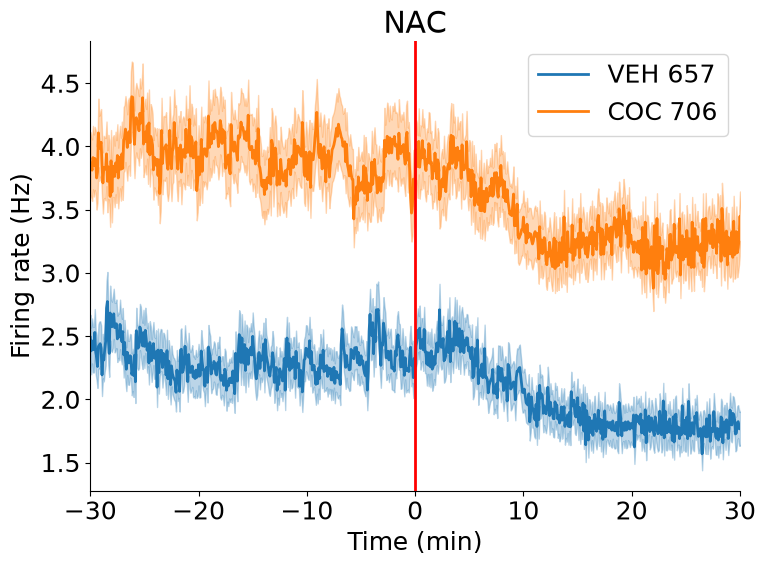

In [20]:
plt.fill_between(bins[:-1]/60,avg_VEH_time-sem_VEH_time,avg_VEH_time+sem_VEH_time, alpha=0.3,color=color_VEH)
plt.plot(bins[:-1]/60,avg_VEH_time, lw=2,label="VEH {}".format(len(fr_VEH)), color=color_VEH)

plt.fill_between(bins[:-1]/60,avg_COC_time-sem_COC_time,avg_COC_time+sem_COC_time, alpha=0.3,color=color_COC)
plt.plot(bins[:-1]/60,avg_COC_time, lw=2,label="COC {}".format(len(fr_COC)), color=color_COC)

plt.xlim(-time_exm/60,time_exm/60)
plt.axvline(0,color="red", lw=2)

plt.ylabel("Firing rate (Hz)")
plt.xlabel("Time (min)")
plt.title(region)
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
# Smooth the population mean and SEM with the same Gaussian kernel.
smooth_avg_VEH_time = np.convolve(avg_VEH_time,gaussian_kernel,'same')
smooth_sem_VEH_time = np.convolve(sem_VEH_time,gaussian_kernel,'same')
smooth_avg_COC_time = np.convolve(avg_COC_time,gaussian_kernel,'same')
smooth_sem_COC_time = np.convolve(sem_COC_time,gaussian_kernel,'same')

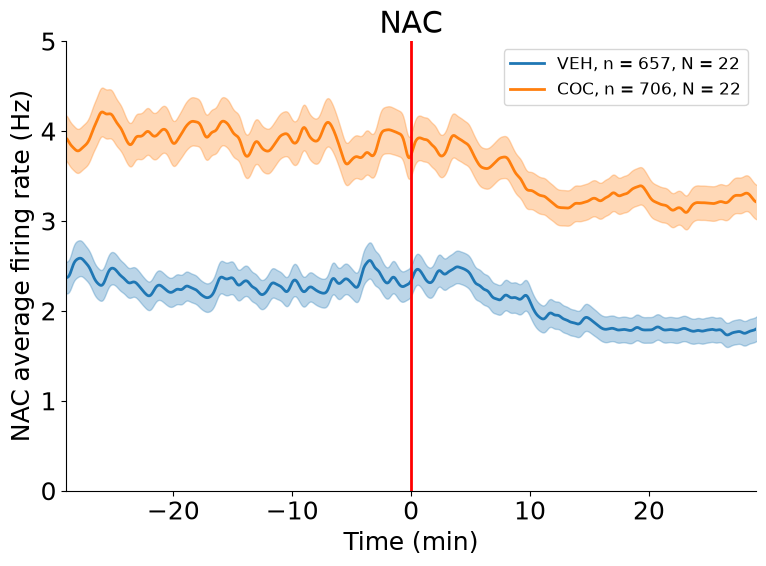

In [22]:
# Figure 2C: smoothed population firing-rate time course.
plt.fill_between(bins[:-1]/60,smooth_avg_VEH_time-smooth_sem_VEH_time,smooth_avg_VEH_time+smooth_sem_VEH_time, alpha=0.3,color=color_VEH)
plt.plot(bins[:-1]/60,smooth_avg_VEH_time, lw=2,label="VEH, n = {}, N = {}".format(len(fr_VEH), len(files_VEH)), color=color_VEH)

plt.fill_between(bins[:-1]/60,smooth_avg_COC_time-smooth_sem_COC_time,smooth_avg_COC_time+smooth_sem_COC_time, alpha=0.3,color=color_COC)
plt.plot(bins[:-1]/60,smooth_avg_COC_time, lw=2,label="COC, n = {}, N = {}".format(len(fr_COC), len(files_COC)), color=color_COC)

plt.xlim(-time_exm/60 + 1,time_exm/60 -1)

plt.axvline(0,color="red", lw=2)

plt.ylabel(f"{region} average firing rate (Hz)")
plt.xlabel("Time (min)")
plt.ylim(0,5)
plt.title(region)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

In [23]:
np.mean(avg_VEH_time[:-int(time_exm/bin_time)]), np.mean(avg_COC_time[:-int(time_exm/bin_time)])

(np.float64(2.320205070293451), np.float64(3.9265862499619253))

# Distribution of the population-average firing rate

In [24]:
c_VEH_pre = "navy"
c_VEH_post = "deepskyblue"
c_COC_pre = "darkorange"
c_COC_post = "crimson"



def statis(data1,data2, paired):
    p_shapiro1 = shapiro(data1).pvalue
    p_shapiro2 = shapiro(data2).pvalue
    
    print(p_shapiro1)
    print(p_shapiro2)
    
    if(paired==True):
        if(p_shapiro1>0.05 and p_shapiro2>0.05):
            stat, p = ttest_rel(data1, data2)
            print(ttest_rel(data1, data2))
            
        else:
            stat, p = wilcoxon(data1, data2)
            print(wilcoxon(data1, data2))

    else:
        if(p_shapiro1>0.05 and p_shapiro2>0.05):
            stat, p = ttest_ind(data1, data2)
            print(ttest_ind(data1, data2))
            
        else:
            stat, p = mannwhitneyu(data1, data2)
            print(mannwhitneyu(data1, data2))
            
    return stat, p

3.937824318574092e-06
2.6224524254623737e-15
MannwhitneyuResult(statistic=np.float64(111817.5), pvalue=np.float64(1.0661185701528969e-63))


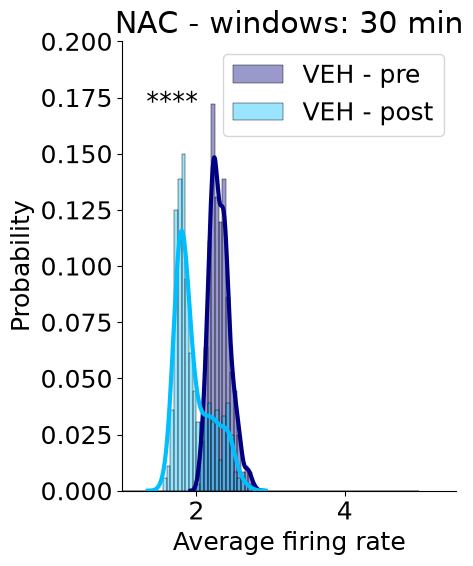

0.6679077678876104
6.188985402555228e-13
MannwhitneyuResult(statistic=np.float64(122162.0), pvalue=np.float64(6.785479627067036e-94))


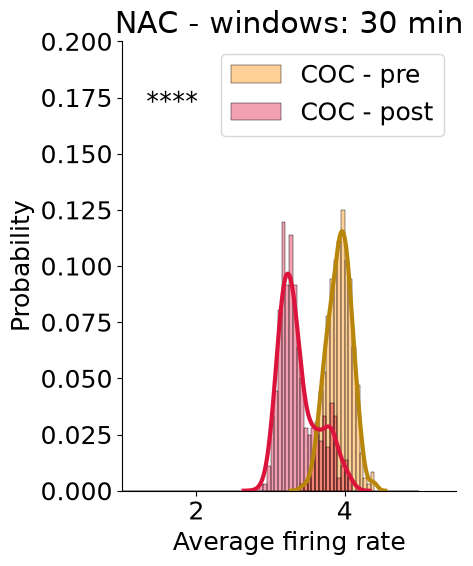

In [25]:
plt.figure(figsize=(5,6))

bin_graph = 0.05

data = avg_VEH_time[:int(time_exm/bin_time)]

kde = sns.kdeplot(data, color=c_VEH_pre, lw=3)
    
data = avg_VEH_time[-int(time_exm/bin_time):]

kde = sns.kdeplot(data, color=c_VEH_post, lw=3)

# Retrieve the KDE curves.
lines = kde.get_lines()

# Rescale each KDE curve to match probability-scaled histogram bins.
for line in lines:
    # Extract the plotted coordinates.
    x = line.get_xdata()
    y = line.get_ydata()

    # Scale the density by the histogram bin width.
    y = y*bin_graph

    # Update the plotted density values.
    line.set_ydata(y)


sns.histplot(avg_VEH_time[:int(time_exm/bin_time)], bins=np.arange(1,5+bin_graph,bin_graph),alpha=0.4,
             stat="probability", color=c_VEH_pre, label = "VEH - pre")

sns.histplot(avg_VEH_time[-int(time_exm/bin_time):], bins=np.arange(1,5+bin_graph,bin_graph),alpha=0.4,
             stat="probability", color=c_VEH_post, label = "VEH - post")
plt.ylim(0,0.2)
plt.xlim(1,5.5)

stat, p = statis(avg_VEH_time[:int(time_exm/bin_time)],avg_VEH_time[-int(time_exm/bin_time):],paired=False)
plt.legend(loc="upper right")
plt.text(0.15,0.85,"****", fontsize=18, ha="center",transform=plt.gca().transAxes)

plt.xlabel("Average firing rate")
plt.ylabel("Probability")
plt.title("{} - windows: {:.0f} min".format(region, time_exm/60))
plt.tight_layout()
plt.show()
# Plot the next comparison.


plt.figure(figsize=(5,6))

bin_graph = 0.05

data = avg_COC_time[:int(time_exm/bin_time)]

kde = sns.kdeplot(data, color="darkgoldenrod", lw=3)
    
data = avg_COC_time[-int(time_exm/bin_time):]

kde = sns.kdeplot(data, color=c_COC_post, lw=3)

# Retrieve the KDE curves.
lines = kde.get_lines()

# Rescale each KDE curve to match probability-scaled histogram bins.
for line in lines:
    # Extract the plotted coordinates.
    x = line.get_xdata()
    y = line.get_ydata()

    # Scale the density by the histogram bin width.
    y = y*bin_graph

    # Update the plotted density values.
    line.set_ydata(y)


sns.histplot(avg_COC_time[:int(time_exm/bin_time)], bins=np.arange(1,5+bin_graph,bin_graph),alpha=0.4,
             stat="probability", color=c_COC_pre, label = "COC - pre")

sns.histplot(avg_COC_time[-int(time_exm/bin_time):], bins=np.arange(1,5+bin_graph,bin_graph),alpha=0.4,
             stat="probability", color=c_COC_post, label = "COC - post")
plt.ylim(0,0.2)
plt.xlim(1,5.5)

stat, p = statis(avg_COC_time[:int(time_exm/bin_time)],avg_COC_time[-int(time_exm/bin_time):],paired=False)
plt.legend(loc="upper right")
plt.text(0.15,0.85,"****", fontsize=18, ha="center",transform=plt.gca().transAxes)

plt.xlabel("Average firing rate")
plt.ylabel("Probability")
plt.title("{} - windows: {:.0f} min".format(region, time_exm/60))
plt.tight_layout()
plt.show()

# Plot the next comparison.

In [26]:
c_VEH_pre = "tab:blue"
c_VEH_post = "tab:blue"
c_COC_pre = "tab:orange"
c_COC_post = "tab:orange"

3.937824318574092e-06
0.6679077678876104
MannwhitneyuResult(statistic=np.float64(0.0), pvalue=np.float64(2.755260278055576e-119))


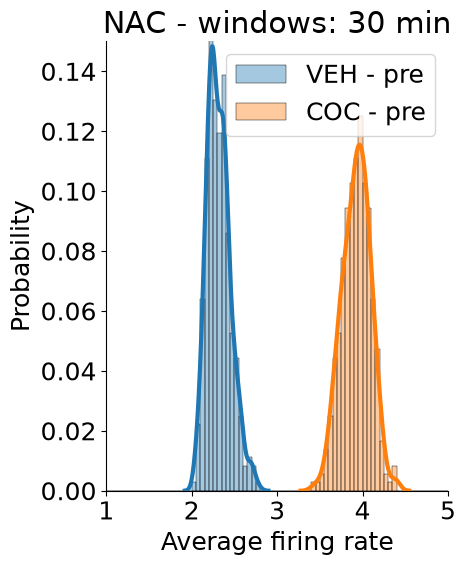

2.6224524254623737e-15
6.188985402555228e-13
MannwhitneyuResult(statistic=np.float64(0.0), pvalue=np.float64(2.755260278055576e-119))


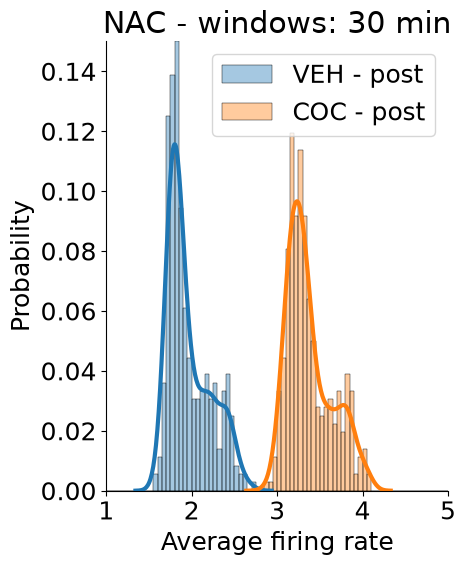

In [27]:
plt.figure(figsize=(5,6))

bin_graph = 0.05

data = avg_VEH_time[:int(time_exm/bin_time)]

kde = sns.kdeplot(data, color=c_VEH_pre, lw=3)
    
data = avg_COC_time[:int(time_exm/bin_time)]

kde = sns.kdeplot(data, color=c_COC_pre, lw=3)

lines = kde.get_lines()

for line in lines:
    x = line.get_xdata()
    y = line.get_ydata()

    y = y*bin_graph

    line.set_ydata(y)


sns.histplot(avg_VEH_time[:int(time_exm/bin_time)], bins=np.arange(1,5+bin_graph,bin_graph),alpha=0.4,
             stat="probability", color=c_VEH_pre, label = "VEH - pre")

sns.histplot(avg_COC_time[:int(time_exm/bin_time)], bins=np.arange(1,5+bin_graph,bin_graph),alpha=0.4,
             stat="probability", color=c_COC_pre, label = "COC - pre")
plt.ylim(0,0.15)
plt.xlim(1,5)

stat, p = statis(avg_VEH_time[:int(time_exm/bin_time)],avg_COC_time[:int(time_exm/bin_time)],paired=False)
plt.legend(loc="upper right")

plt.xlabel("Average firing rate")
plt.ylabel("Probability")
plt.title("{} - windows: {:.0f} min".format(region, time_exm/60))
plt.tight_layout()
plt.show()
# Plot the next comparison.

plt.figure(figsize=(5,6))

bin_graph = 0.05

data = avg_VEH_time[-int(time_exm/bin_time):]

kde = sns.kdeplot(data, color=c_VEH_post, lw=3)
    
data = avg_COC_time[-int(time_exm/bin_time):]

kde = sns.kdeplot(data, color=c_COC_post, lw=3)

# Retrieve the KDE curves.
lines = kde.get_lines()

# Rescale each KDE curve to match probability-scaled histogram bins.
for line in lines:
    # Extract the plotted coordinates.
    x = line.get_xdata()
    y = line.get_ydata()

    # Scale the density by the histogram bin width.
    y = y*bin_graph

    # Update the plotted density values.
    line.set_ydata(y)


sns.histplot(avg_VEH_time[-int(time_exm/bin_time):], bins=np.arange(1,5+bin_graph,bin_graph),alpha=0.4,
             stat="probability", color=c_VEH_post, label = "VEH - post")

sns.histplot(avg_COC_time[-int(time_exm/bin_time):], bins=np.arange(1,5+bin_graph,bin_graph),alpha=0.4,
             stat="probability", color=c_COC_post, label = "COC - post")
plt.ylim(0,0.15)
plt.xlim(1,5)

stat, p = statis(avg_VEH_time[-int(time_exm/bin_time):],avg_COC_time[-int(time_exm/bin_time):],paired=False)
plt.legend(loc="upper right")

plt.xlabel("Average firing rate")
plt.ylabel("Probability")
plt.title("{} - windows: {:.0f} min".format(region, time_exm/60))
plt.tight_layout()
plt.show()
# Plot the next comparison.

In [28]:
# Calculate mean firing rates in the pre- and post-injection windows.

avg_VEH_windows_baseline = []
avg_VEH_windows_after = []
classification_VEH = []
zscore_VEH = []

for i in range(len(fr_VEH)):
    aux_baseline = fr_VEH[i][:int(time_exm/bin_time)]
    aux_after = fr_VEH[i][-int(time_exm/bin_time):]
    
    avg_baseline = np.mean(aux_baseline)
    std_baseline = np.std(aux_baseline)
    
    if(std_baseline==0 or np.isnan(std_baseline)):
        a = 0
    else:
        zscore_VEH.append((fr_VEH[i]-avg_baseline)/std_baseline)
    
    avg_VEH_windows_baseline.append(np.mean(aux_baseline))
    avg_VEH_windows_after.append(np.mean(aux_after))
    
    shapiro_baseline = shapiro(aux_baseline).pvalue
    shapiro_after = shapiro(aux_after).pvalue
        
    if(shapiro_baseline>0.05 and shapiro_after>0.05):
        stat, p_val = stats.ttest_ind(aux_baseline, aux_after)
        
        if(p_val<0.05):
            if((np.mean(aux_after)-np.mean(aux_baseline))>0):
                classification_VEH.append(1)
            else:
                classification_VEH.append(-1)
                
        else:
            classification_VEH.append(0)
            
    else:
        stat, p_val = mannwhitneyu(aux_baseline, aux_after)
        
        if(p_val<0.05):
            if((np.mean(aux_after)-np.mean(aux_baseline))>0):
                classification_VEH.append(1)
            else:
                classification_VEH.append(-1)
                
        else:
            classification_VEH.append(0)
        

# Calculate mean firing rates in the pre- and post-injection windows.

avg_COC_windows_baseline = []
avg_COC_windows_after = []
classification_COC = []
zscore_COC = []

for i in range(len(fr_COC)):
    aux_baseline = fr_COC[i][:int(time_exm/bin_time)]
    aux_after = fr_COC[i][-int(time_exm/bin_time):]
    
    avg_baseline = np.mean(aux_baseline)
    std_baseline = np.std(aux_baseline)
    
    if(std_baseline==0 or np.isnan(std_baseline)):
        a = 0
    else:
        zscore_COC.append((fr_COC[i]-avg_baseline)/std_baseline)
    
    avg_COC_windows_baseline.append(np.mean(aux_baseline))
    avg_COC_windows_after.append(np.mean(aux_after))
    
    shapiro_baseline = shapiro(aux_baseline).pvalue
    shapiro_after = shapiro(aux_after).pvalue
        
    if(shapiro_baseline>0.05 and shapiro_after>0.05):
        stat, p_val = stats.ttest_ind(aux_baseline, aux_after)
        
        if(p_val<0.05):
            if((np.mean(aux_after)-np.mean(aux_baseline))>0):
                classification_COC.append(1)
            else:
                classification_COC.append(-1)
                
        else:
            classification_COC.append(0)
            
    else:
        stat, p_val = mannwhitneyu(aux_baseline, aux_after)
        
        if(p_val<0.05):
            if((np.mean(aux_after)-np.mean(aux_baseline))>0):
                classification_COC.append(1)
            else:
                classification_COC.append(-1)
                
        else:
            classification_COC.append(0)

/home/mirtilo/miniconda3/envs/phy3/lib/python3.12/site-packages/scipy/stats/_morestats.py:2199: RuntimeWarning: invalid value encountered in scalar divide
  return num / den


# Distribution of individual-neuron firing rates

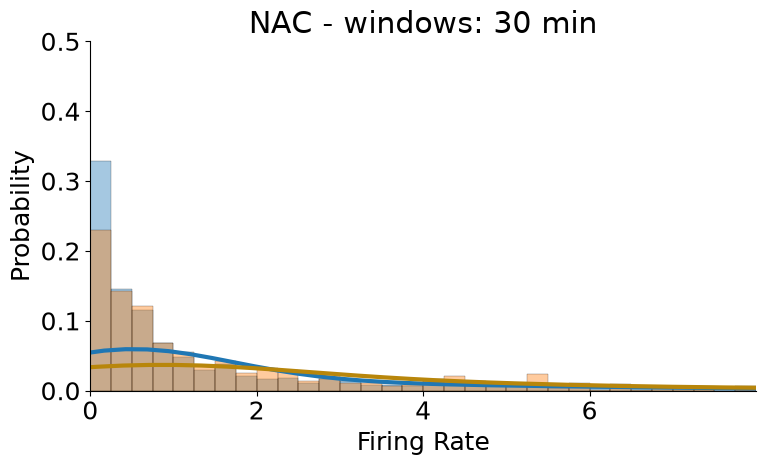

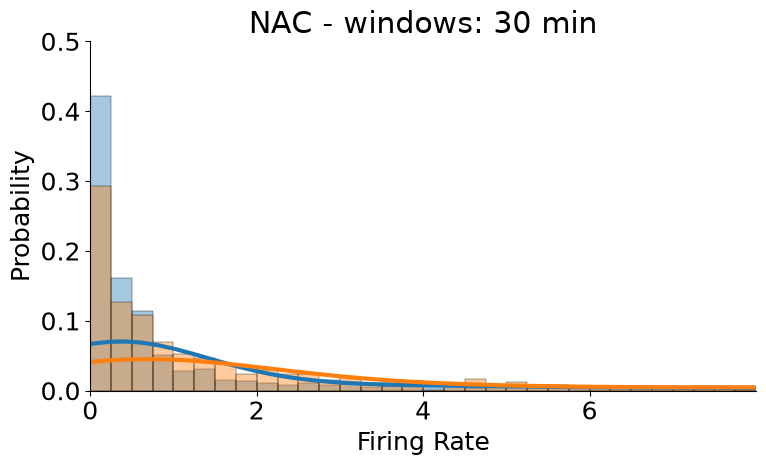

In [29]:
plt.figure(figsize=(8,5))

bin_graph = 0.25

data = avg_VEH_windows_baseline

kde = sns.kdeplot(data, color=c_VEH_pre, lw=3)

data = avg_COC_windows_baseline

kde = sns.kdeplot(data, color="darkgoldenrod", lw=3)
    


# Retrieve the KDE curves.
lines = kde.get_lines()

# Rescale each KDE curve to match probability-scaled histogram bins.
for line in lines:
    # Extract the plotted coordinates.
    x = line.get_xdata()
    y = line.get_ydata()

    # Scale the density by the histogram bin width.
    y = y*bin_graph

    # Update the plotted density values.
    line.set_ydata(y)

sns.histplot(avg_VEH_windows_baseline, bins=np.arange(0,8+bin_graph,bin_graph),alpha=0.4,
             stat="probability", color=c_VEH_pre, label = "VEH - pre")
    
sns.histplot(avg_COC_windows_baseline, bins=np.arange(0,8+bin_graph,bin_graph),alpha=0.4,
             stat="probability", color=c_COC_pre, label = "COC - pre")


plt.ylim(0,0.5)
plt.xlim(0,8)
plt.xticks(np.arange(0, 8, 2))

plt.xlabel("Firing Rate")
plt.ylabel("Probability")
plt.title("{} - windows: {:.0f} min".format(region, time_exm/60))
plt.tight_layout()
plt.show()


plt.figure(figsize=(8,5))

bin_graph = 0.25

data = avg_VEH_windows_after

kde = sns.kdeplot(data, color=c_VEH_post, lw=3)

data = avg_COC_windows_after

kde = sns.kdeplot(data, color=c_COC_post, lw=3)
    


# Retrieve the KDE curves.
lines = kde.get_lines()

# Rescale each KDE curve to match probability-scaled histogram bins.
for line in lines:
    # Extract the plotted coordinates.
    x = line.get_xdata()
    y = line.get_ydata()

    # Scale the density by the histogram bin width.
    y = y*bin_graph

    # Update the plotted density values.
    line.set_ydata(y)

sns.histplot(avg_VEH_windows_after, bins=np.arange(0,8+bin_graph,bin_graph),alpha=0.4,
             stat="probability", color=c_VEH_post, label = "VEH - post")
    
sns.histplot(avg_COC_windows_after, bins=np.arange(0,8+bin_graph,bin_graph),alpha=0.4,
             stat="probability", color=c_COC_post, label = "COC - post")


plt.ylim(0,0.5)
plt.xlim(0,8)
plt.xticks(np.arange(0, 8, 2))

plt.xlabel("Firing Rate")
plt.ylabel("Probability")
plt.title("{} - windows: {:.0f} min".format(region, time_exm/60))
plt.tight_layout()
plt.show()

# Supplementary Fig. S1 — Percentage of neuronal responses

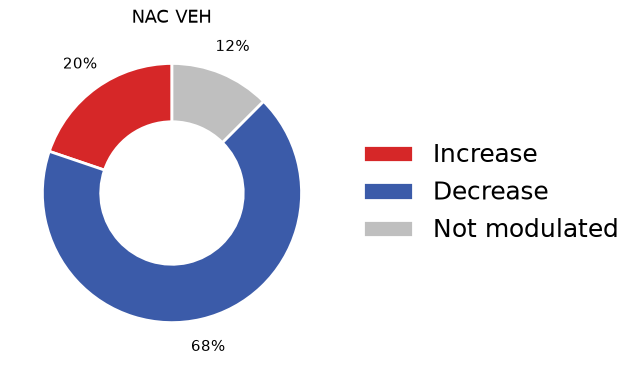

In [30]:

def func(pct, allvalues):
    absolute = int(np.round(pct / 100. * np.sum(allvalues)))
    return "{:.0f}%\n({:d})".format(pct, absolute)

outcome_list = collections.Counter(classification_VEH)
frequency = []
try:
    frequency.append(outcome_list[-1])
except:
    frequency.append(0)

try:
    frequency.append(outcome_list[0])
except:
    frequency.append(0)

try:
    frequency.append(outcome_list[1])
except:
    frequency.append(0) 
    
frequency_VEH = frequency


# Arrange response counts as increase, decrease, and not modulated.
data = [frequency[2], frequency[0], frequency[1]]
total = np.sum(data)

# Use the color scheme from the article.
colors = ["#d62728", "#3b5ba9", "#bfbfbf"]   # vermelho, azul, cinza

fig, ax = plt.subplots(figsize=(7,4))

wedges, texts, autotexts = ax.pie(
    data,
    colors=colors,
    startangle=90,
    labels=None,
    autopct=lambda pct: f"{pct:.0f}%",
    pctdistance=1.22,
    wedgeprops=dict(width=0.45, edgecolor="white", linewidth=2)
)


# Format percentage labels.
plt.setp(autotexts,
         fontsize=11,
         color="black")

ax.set_aspect("equal")

# Add the panel title.
plt.title(f"{region} VEH", fontsize=13)

# Add response-category labels.
ax.legend(
    wedges,
    ["Increase","Decrease","Not modulated"],
    loc="center left",
    bbox_to_anchor=(1.02,0.5),
    frameon=False
)

plt.tight_layout()
plt.show()

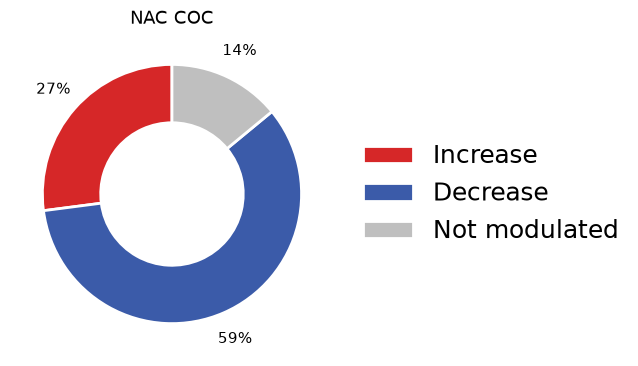

In [31]:
def func(pct, allvalues):
    absolute = int(np.round(pct / 100. * np.sum(allvalues)))
    return "{:.0f}%\n({:d})".format(pct, absolute)

outcome_list = collections.Counter(classification_COC)
frequency = []
try:
    frequency.append(outcome_list[-1])
except:
    frequency.append(0)

try:
    frequency.append(outcome_list[0])
except:
    frequency.append(0)

try:
    frequency.append(outcome_list[1])
except:
    frequency.append(0) 
    
frequency_VEH = frequency


# Arrange response counts as increase, decrease, and not modulated.
data = [frequency[2], frequency[0], frequency[1]]
total = np.sum(data)

# Use the color scheme from the article.
colors = ["#d62728", "#3b5ba9", "#bfbfbf"]   # vermelho, azul, cinza

fig, ax = plt.subplots(figsize=(7,4))

wedges, texts, autotexts = ax.pie(
    data,
    colors=colors,
    startangle=90,
    labels=None,
    autopct=lambda pct: f"{pct:.0f}%",
    pctdistance=1.22,
    wedgeprops=dict(width=0.45, edgecolor="white", linewidth=2)
)


# Format percentage labels.
plt.setp(autotexts,
         fontsize=11,
         color="black")

ax.set_aspect("equal")

# Add the panel title.
plt.title(f"{region} COC", fontsize=13)

# Add response-category labels.
ax.legend(
    wedges,
    ["Increase","Decrease","Not modulated"],
    loc="center left",
    bbox_to_anchor=(1.02,0.5),
    frameon=False
)

plt.tight_layout()
plt.show()

# Neuronal-response heatmaps

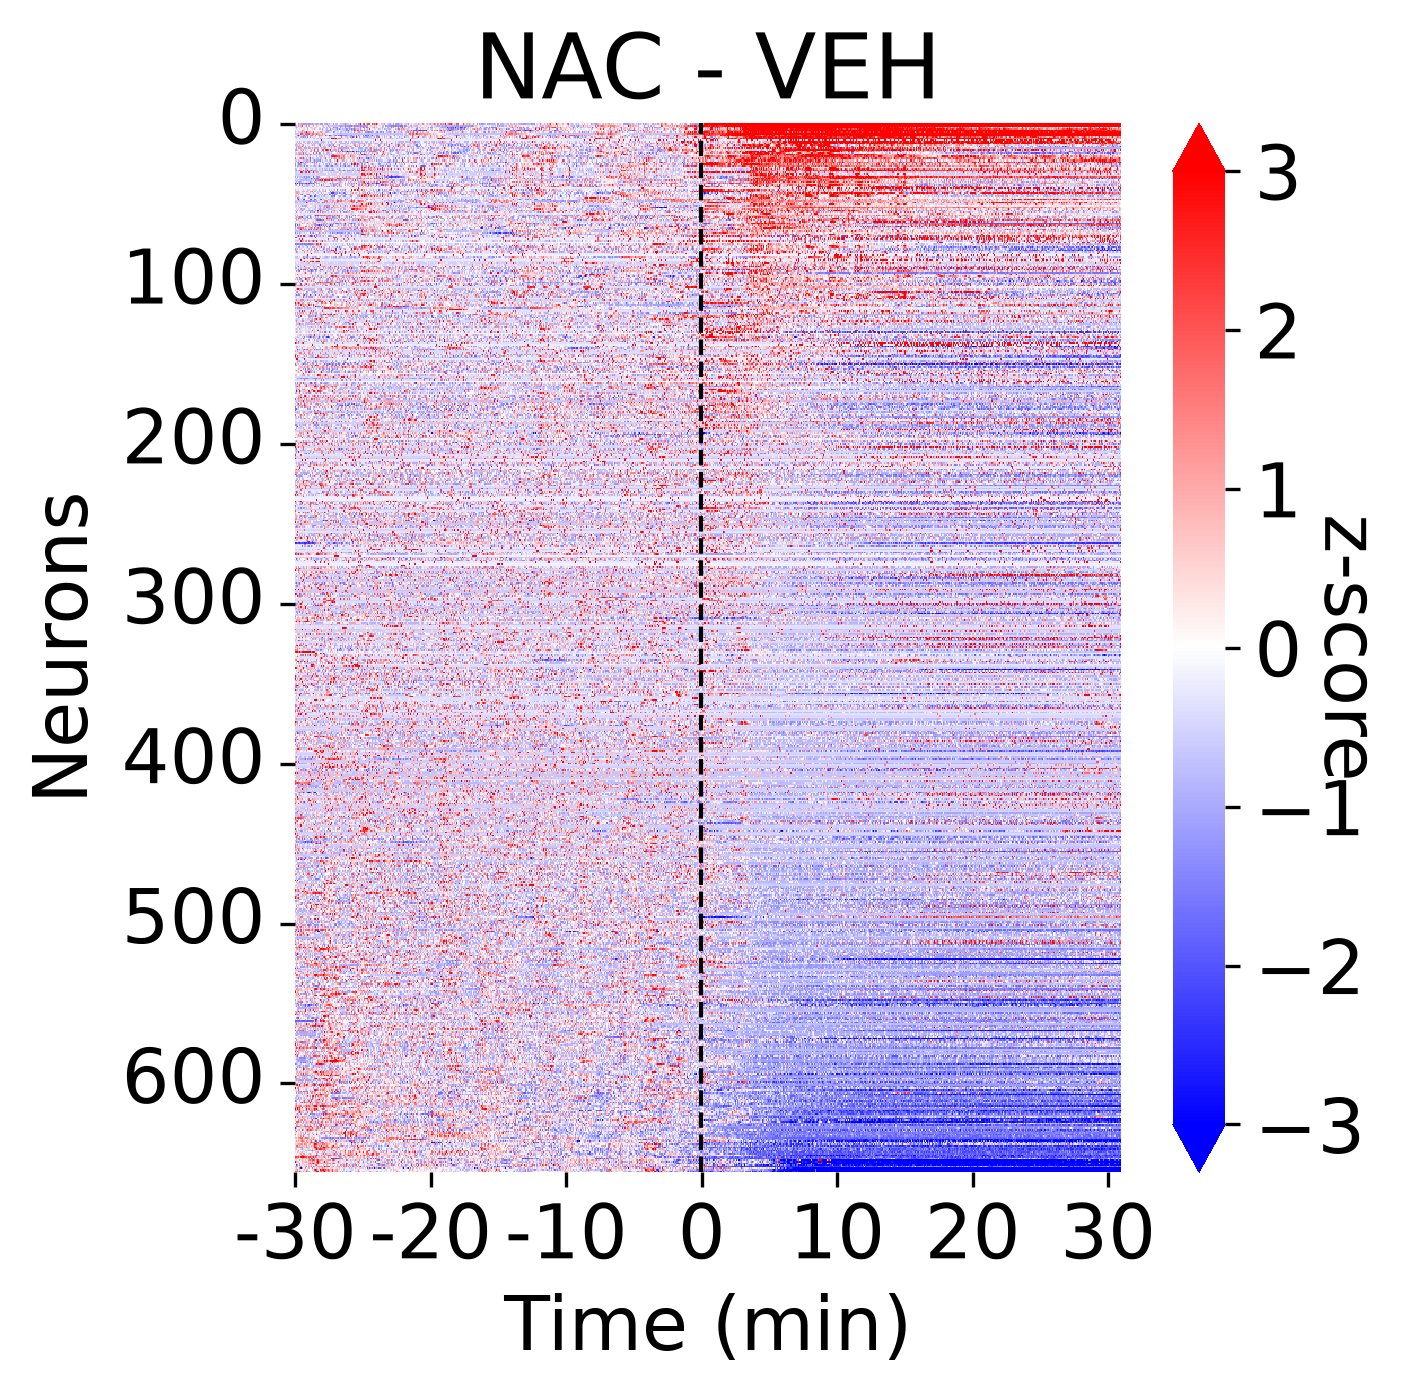

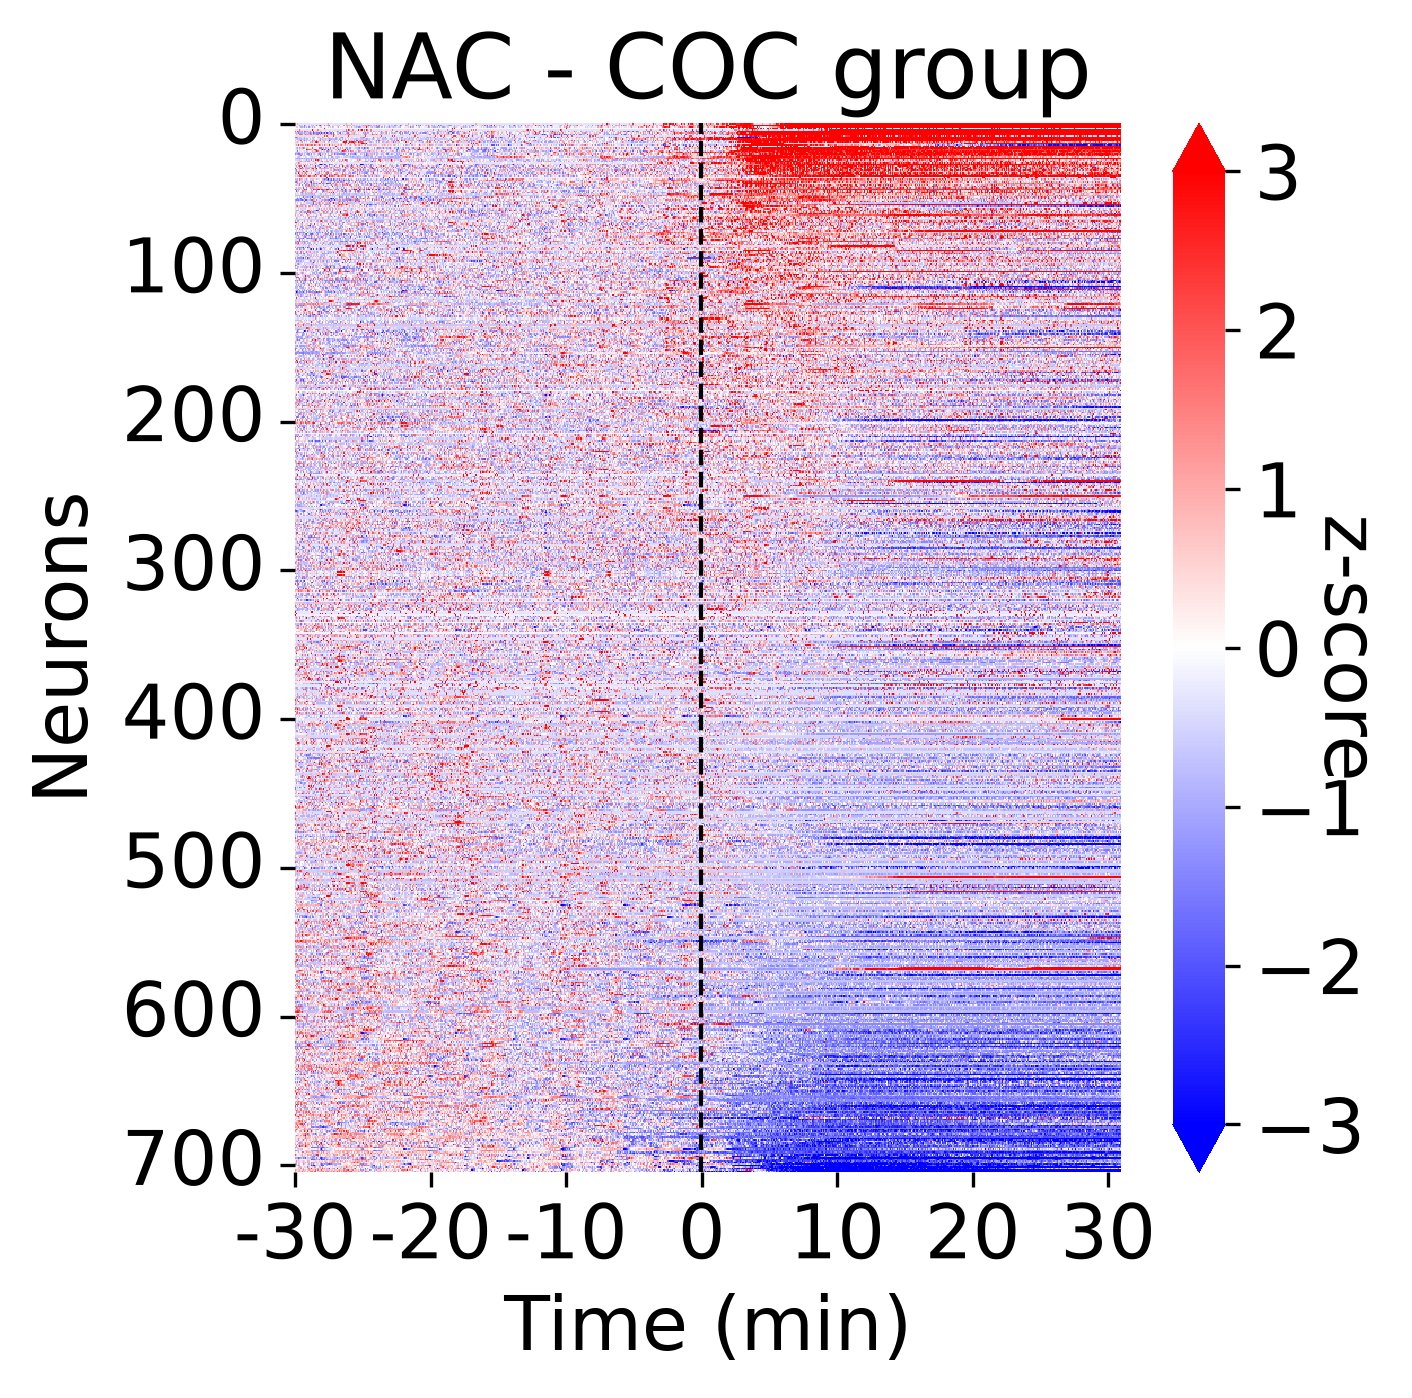

In [32]:

plt.figure(figsize=(5, 5), dpi=300)

zscore_VEH = np.array(zscore_VEH)

aux_sort = np.argsort(np.mean(zscore_VEH[:,-(int(time_exm/bin_time)):-(int(time_exm/bin_time))+int(10*60/bin_time)],axis=1))

axx= sns.heatmap(zscore_VEH[aux_sort[::-1]], vmax=3,vmin=-3, cmap="bwr",cbar_kws={"extend":"both",'label': 'z-score'})
cbar = axx.collections[0].colorbar
cbar.ax.yaxis.label.set_rotation(270)

plt.yticks(np.arange(0,zscore_VEH.shape[0],100)+0.5,np.arange(0,zscore_VEH.shape[0],100), rotation=0)
plt.xticks(np.arange(0,zscore_VEH.shape[1],int(10*60/bin_time))+0.5,np.around((np.arange(0,zscore_VEH.shape[1],int(10*60/bin_time))*bin_time-time_exm)/60,0).astype(int), rotation=0)

plt.axvline(time_exm/bin_time, color="k", lw=1, ls="--")
plt.ylabel("Neurons")
plt.xlabel("Time (min)")
plt.title("{} - {}".format(region, "VEH"))

step_y = 100

plt.yticks(
    np.arange(0, zscore_VEH.shape[0], step_y) + 0.5,
    np.arange(0, zscore_VEH.shape[0], step_y),
    rotation=0
)

plt.tight_layout()




plt.show()


plt.figure(figsize=(5, 5), dpi=300)

zscore_COC = np.array(zscore_COC)

aux_sort = np.argsort(np.mean(zscore_COC[:,-(int(time_exm/bin_time)):-(int(time_exm/bin_time))+int(10*60/bin_time)],axis=1))

axx= sns.heatmap(zscore_COC[aux_sort[::-1]], vmax=3,vmin=-3, cmap="bwr",cbar_kws={"extend":"both",'label': 'z-score'})
cbar = axx.collections[0].colorbar
cbar.ax.yaxis.label.set_rotation(270)

plt.yticks(np.arange(0,zscore_COC.shape[0],50)+0.5,np.arange(0,zscore_COC.shape[0],50), rotation=0)
plt.xticks(np.arange(0,zscore_COC.shape[1],int(10*60/bin_time))+0.5,np.around((np.arange(0,zscore_COC.shape[1],int(10*60/bin_time))*bin_time-time_exm)/60,0).astype(int), rotation=0)
plt.axvline(time_exm/bin_time, color="k", lw=1, ls="--")

plt.ylabel("Neurons")
plt.xlabel("Time (min)")
plt.title("{} - {} group".format(region, "COC"))
plt.yticks(
    np.arange(0, zscore_COC.shape[0], step_y) + 0.5,
    np.arange(0, zscore_COC.shape[0], step_y),
    rotation=0
)


plt.tight_layout()


plt.show()

# Distribution of the firing-rate index

<Figure size 1500x1500 with 0 Axes>

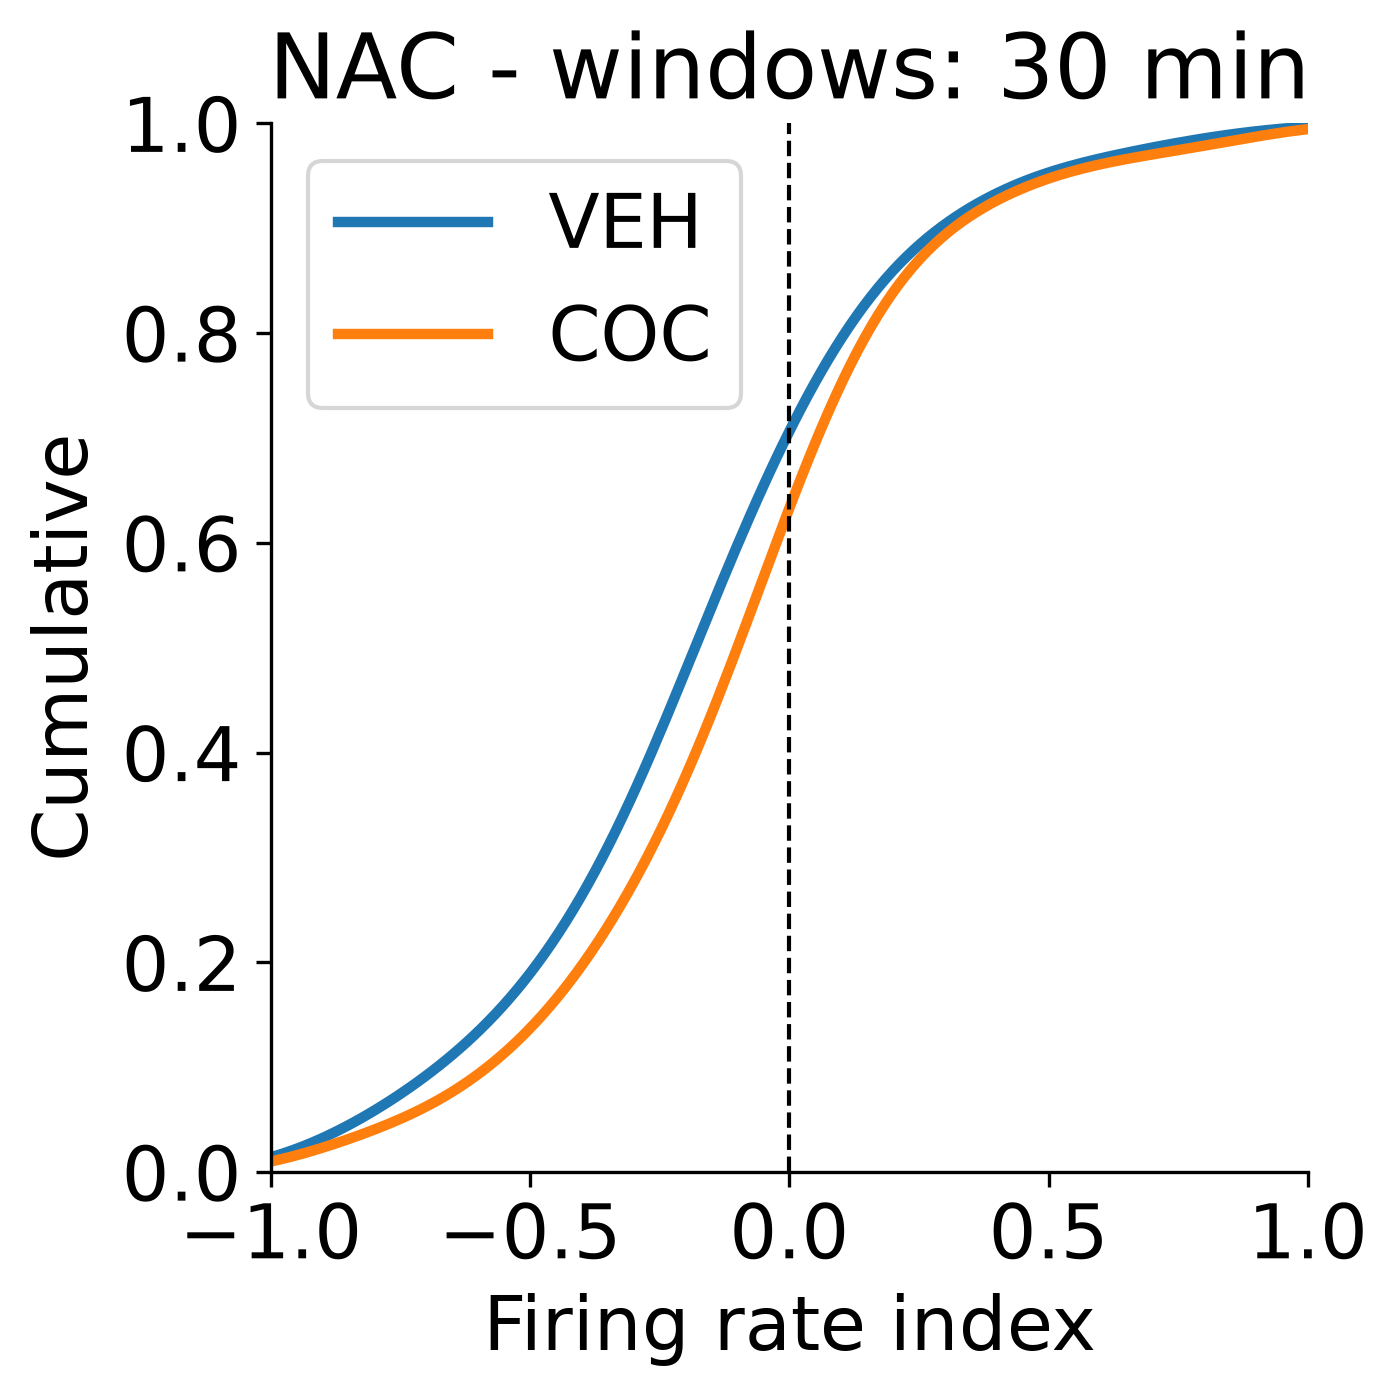

In [33]:
plt.figure(figsize=(5, 5), dpi=300)


f_index_VEH = []
for i in range(len(avg_VEH_windows_after)):
    if(avg_VEH_windows_after[i]==0 and avg_VEH_windows_baseline[i]==0):
        a=0
    else:
        f_index_VEH.append((avg_VEH_windows_after[i]-avg_VEH_windows_baseline[i])/(avg_VEH_windows_after[i]+avg_VEH_windows_baseline[i]))

f_index_COC = []
for i in range(len(avg_COC_windows_after)):
    if(avg_COC_windows_after[i]==0 and avg_COC_windows_baseline[i]==0):
        a=0
    else:
        f_index_COC.append((avg_COC_windows_after[i]-avg_COC_windows_baseline[i])/(avg_COC_windows_after[i]+avg_COC_windows_baseline[i]))

# Plot the next comparison.


plt.figure(figsize=(5, 5), dpi=300)

# Vehicle group
sns.kdeplot(
    x=f_index_VEH,
    cumulative=True,
    common_norm=False,
    bw_adjust=1.2,
    linewidth=2.5,
    label="VEH"
)

# Cocaine group
sns.kdeplot(
    x=f_index_COC,
    cumulative=True,
    common_norm=False,
    bw_adjust=1.2,
    linewidth=2.5,
    label="COC"
)

plt.axvline(0, color="k", lw=1, ls="--")
plt.title(f"{region} - windows: {time_exm/60:.0f} min")
plt.xlim(-1, 1)
plt.ylim(0, 1)

plt.xlabel("Firing rate index")
plt.ylabel("Cumulative")
plt.legend()
plt.tight_layout()
plt.show()

p-value: 5.527276772352862e-06
p-value: 4.332255095435638e-09
4.319735773109457e-05


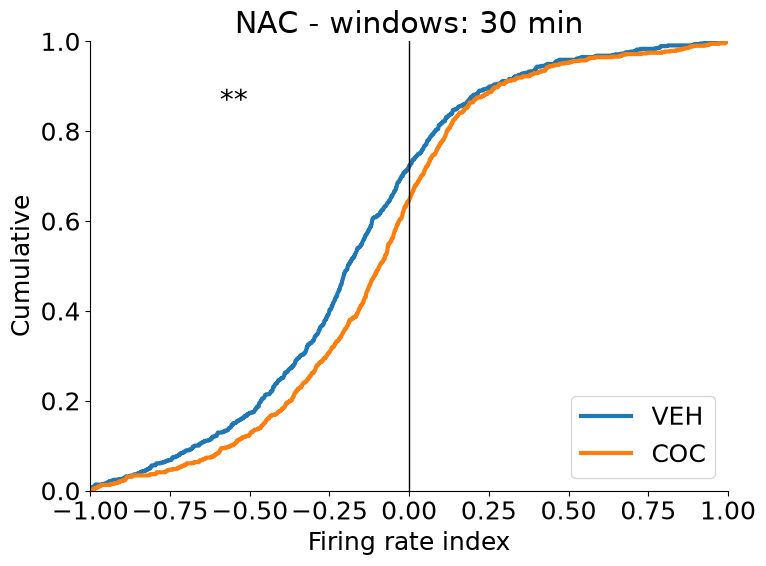

In [34]:
f_index_VEH = []
for i in range(len(avg_VEH_windows_after)):
    if(avg_VEH_windows_after[i]==0 and avg_VEH_windows_baseline[i]==0):
        a=0
    else:
        f_index_VEH.append((avg_VEH_windows_after[i]-avg_VEH_windows_baseline[i])/(avg_VEH_windows_after[i]+avg_VEH_windows_baseline[i]))

f_index_COC = []
for i in range(len(avg_COC_windows_after)):
    if(avg_COC_windows_after[i]==0 and avg_COC_windows_baseline[i]==0):
        a=0
    else:
        f_index_COC.append((avg_COC_windows_after[i]-avg_COC_windows_baseline[i])/(avg_COC_windows_after[i]+avg_COC_windows_baseline[i]))

# Plot the next comparison.

data_f = [f_index_VEH,f_index_COC]

np.random.seed(0)

for i in data_f:
    stat, p_valor = shapiro(i)

    # Print the normality-test results.
    print("p-value:", p_valor)
    
statss, p_val = mannwhitneyu(f_index_VEH,f_index_COC)
print(p_val)
plt.text(-0.55,0.85,"**",ha='center', fontsize=20)

bin_cum = 0.001
labelss = ["VEH", "COC"]
for i in range(len(data_f)):
    hist, bin_edges = np.histogram(data_f[i], bins=np.arange(-1,1+bin_cum,bin_cum), density=True)
    plt.plot(bin_edges[1:], np.cumsum(hist)*bin_cum,lw=3,label=labelss[i])
    
plt.legend()
plt.axvline(0, color="k", lw=1)
plt.title("{} - windows: {:.0f} min".format(region,time_exm/60))
plt.xlim(-1,1)
plt.ylim(0,1)

plt.xlabel("Firing rate index")
plt.ylabel("Cumulative")

plt.tight_layout()
plt.show()